> **Reference copy with outputs.** This notebook was run on Wolverine Glacier on 2026-10-22 (OGGM 1.6.3, preprocessed level 4, W5E5). It shows what the notebook should produce. To run it yourself, open [`notebooks/06_publication_figures.ipynb`](../notebooks/06_publication_figures.ipynb), not this copy.

# 06 · Figures for talks and papers

Recipes for multi-panel figures built from the runs of notebooks 03 and 04. Run those first:
this notebook only reads their output. Every figure is saved as PNG (300 dpi) and PDF (vector,
editable text) in `config.FIG_DIR`. Switch `CONTEXT` to `"talk"` for slides.

Conventions (from `wolverine_oggm.plotting`):

* teal = rain, pink = snow, violet = mixed, matching schnaps-borah's rain/snow maps
* Okabe–Ito colours for scenarios (colour-blind safe), panel letters (a), (b), …
* journal widths: 3.5 in (one column) and 7.2 in (two columns)

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath(".."))
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from oggm import cfg, graphics

from wolverine_oggm import config, experiments, massbalance, phase, plotting

warnings.filterwarnings("ignore")
CONTEXT = "paper"
plotting.set_style(CONTEXT)
gdir = config.get_glacier_directory()
print("Figures go to", config.FIG_DIR)


def have(suffix):
    return os.path.exists(gdir.get_filepath("model_diagnostics", filesuffix=suffix))


missing = [s for s in ("_h3_0", "_h5_0") if not have(s)]
if missing:
    raise RuntimeError(f"Run notebooks 03 and 04 first (missing outputs {missing})")

Figures go to /tmp/claude-0/wfigs


## Figure 1: study glacier and model setup

['/tmp/claude-0/wfigs/fig1_setup.png', '/tmp/claude-0/wfigs/fig1_setup.pdf']

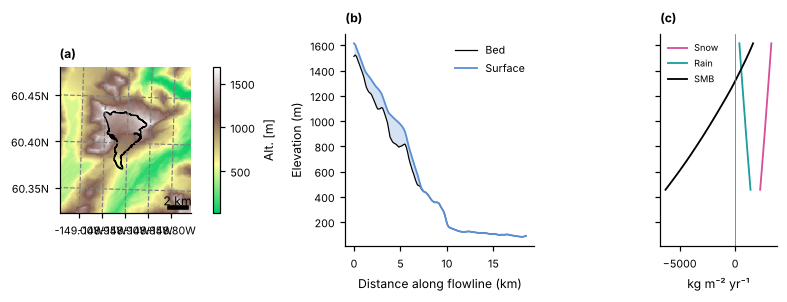

In [2]:
fl = gdir.read_pickle("model_flowlines")[-1]
mb = massbalance.phase_model_class(calib_suffix="_ph4", phase_curve=phase.STANDARD_CURVES["oggm"],
                                   temp_std=config.daily_temp_spread(gdir))(gdir)
y0, y1 = config.calibration_years()
hh = np.linspace(fl.surface_h[fl.thick > 0].min(), fl.surface_h.max(), 30)
smb = np.mean([mb.get_annual_mb(hh, y) for y in range(y0, y1 + 1)], axis=0) * cfg.SEC_IN_YEAR * mb.rho
cl = np.mean([np.array(mb.get_annual_climate(hh, y)) for y in range(y0, y1 + 1)], axis=0)

fig = plt.figure(figsize=(plotting.WIDTH_2COL, 2.8))
gs = fig.add_gridspec(1, 3, width_ratios=[1.1, 1.3, 0.8])
ax0 = fig.add_subplot(gs[0])
graphics.plot_domain(gdir, ax=ax0)
ax0.set_title("")
ax1 = fig.add_subplot(gs[1])
plotting.flowline_profile(ax1, fl)
ax1.legend(frameon=False, loc="upper right")
ax2 = fig.add_subplot(gs[2], sharey=ax1)
ax2.plot(cl[3], hh, color=plotting.SNOW, label="Snow")
ax2.plot(cl[2] - cl[3], hh, color=plotting.RAIN, label="Rain")
ax2.plot(smb, hh, color="k", label="SMB")
ax2.axvline(0, color=plotting.GREY, lw=0.5)
ax2.set_xlabel("kg m⁻² yr⁻¹")
ax2.legend(frameon=False, fontsize=6)
plt.setp(ax2.get_yticklabels(), visible=False)
plotting.label_panels([ax0, ax1, ax2], x=0.0)
fig.tight_layout()
plotting.test_mode_note(fig)
plotting.savefig(fig, "fig1_setup")

## Figure 2: how much of the warming response is the loss of snowfall? (H3)

['/tmp/claude-0/wfigs/fig2_phase_share_of_warming.png',
 '/tmp/claude-0/wfigs/fig2_phase_share_of_warming.pdf']

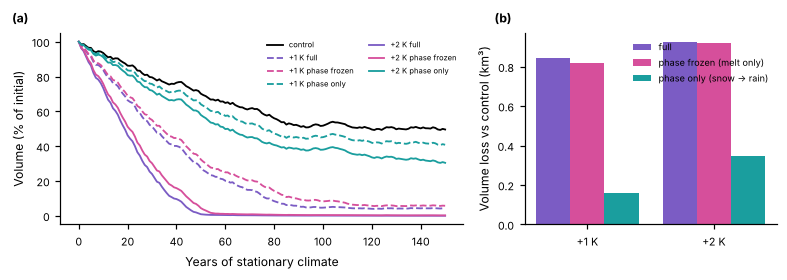

In [3]:
labels = ["control", "+1 K full", "+1 K phase frozen", "+1 K phase only",
          "+2 K full", "+2 K phase frozen", "+2 K phase only"]
sums = {lab: experiments.summary(gdir, f"_h3_{k}") for k, lab in enumerate(labels)}
colors = {"control": "k", "full": plotting.MIXED, "phase frozen": plotting.SNOW, "phase only": plotting.RAIN}

fig, axes = plt.subplots(1, 2, figsize=(plotting.WIDTH_2COL, 2.6), gridspec_kw={"width_ratios": [1.6, 1]})
for lab, d in sums.items():
    kind = "control" if lab == "control" else lab.split(" K ")[1]
    ls = "--" if lab.startswith("+1") else "-"
    axes[0].plot(d.index - d.index[0], d.volume_km3 / d.volume_km3.iloc[0] * 100, color=colors[kind], ls=ls, label=lab)
axes[0].set_xlabel("Years of stationary climate")
axes[0].set_ylabel("Volume (% of initial)")
axes[0].legend(frameon=False, fontsize=5, ncol=2)
end = {lab: d.volume_km3.iloc[-10:].mean() for lab, d in sums.items()}
x = np.arange(2)
loss_full = [end["control"] - end[f"+{t} K full"] for t in (1, 2)]
loss_only = [end["control"] - end[f"+{t} K phase only"] for t in (1, 2)]
loss_frozen = [end["control"] - end[f"+{t} K phase frozen"] for t in (1, 2)]
wd = 0.27
axes[1].bar(x - wd, loss_full, wd, color=plotting.MIXED, label="full")
axes[1].bar(x, loss_frozen, wd, color=plotting.SNOW, label="phase frozen (melt only)")
axes[1].bar(x + wd, loss_only, wd, color=plotting.RAIN, label="phase only (snow → rain)")
axes[1].set_xticks(x, ["+1 K", "+2 K"])
axes[1].set_ylabel("Volume loss vs control (km³)")
axes[1].legend(frameon=False, fontsize=6)
plotting.label_panels(axes)
fig.tight_layout()
plotting.test_mode_note(fig)
plotting.savefig(fig, "fig2_phase_share_of_warming")

## Figure 3: velocity follows geometry (H3, +2 K full vs control)

['/tmp/claude-0/wfigs/fig3_velocity_hovmoller.png',
 '/tmp/claude-0/wfigs/fig3_velocity_hovmoller.pdf']

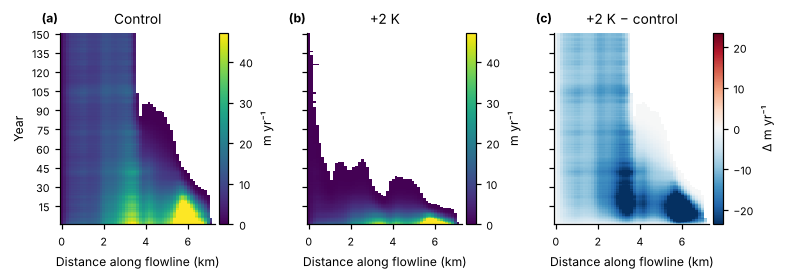

In [4]:
a = experiments.fl_diagnostics(gdir, "_h3_0")
b = experiments.fl_diagnostics(gdir, "_h3_4")
va = a["ice_velocity_myr"].where(a["thickness_m"] > 1).isel(time=slice(1, None))
vb = b["ice_velocity_myr"].where(b["thickness_m"] > 1).isel(time=slice(1, None))
vmax = float(np.nanpercentile(va, 98))
fig, axes = plt.subplots(1, 3, figsize=(plotting.WIDTH_2COL, 2.6), sharey=True)
plotting.hovmoller(axes[0], va, vmin=0, vmax=vmax, label="m yr⁻¹")
plotting.hovmoller(axes[1], vb, vmin=0, vmax=vmax, label="m yr⁻¹")
plotting.hovmoller(axes[2], (vb.fillna(0) - va.fillna(0)).where(va.notnull() | vb.notnull()), cmap="RdBu_r",
                   vmin=-vmax / 2, vmax=vmax / 2, label="Δ m yr⁻¹")
for ax, t in zip(axes, ("Control", "+2 K", "+2 K − control")):
    ax.set_title(t)
for ax in axes[1:]:
    ax.set_ylabel("")
plotting.label_panels(axes)
fig.tight_layout()
plotting.test_mode_note(fig)
plotting.savefig(fig, "fig3_velocity_hovmoller")

## Figure 4: seasonal velocity under water-driven sliding (H5)

['/tmp/claude-0/wfigs/fig4_seasonal_velocity.png',
 '/tmp/claude-0/wfigs/fig4_seasonal_velocity.pdf']

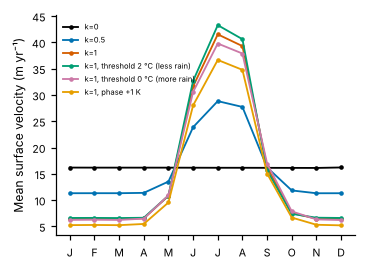

In [5]:
h5_labels = ["k=0", "k=0.5", "k=1", "k=1, threshold 2 °C (less rain)", "k=1, threshold 0 °C (more rain)", "k=1, phase +1 K"]


def seasonal(suffix, last_years=10):
    d = experiments.summary(gdir, suffix)
    d = d[d.index >= d.index.max() - last_years]
    month = (np.round(((d.index.values - 1 / 12) % 1) * 12).astype(int) % 12) + 1
    return d.groupby(month)["velocity_mean_myr"].mean()


fig, ax = plt.subplots(figsize=(plotting.WIDTH_1COL, 2.6))
for k, lab in enumerate(h5_labels):
    if have(f"_h5_{k}"):
        s = seasonal(f"_h5_{k}")
        ax.plot(s.index, s.values, "-o", ms=2, label=lab)
ax.set_xticks(range(1, 13), list("JFMAMJJASOND"))
ax.set_ylabel("Mean surface velocity (m yr⁻¹)")
ax.legend(frameon=False, fontsize=5)
plotting.test_mode_note(fig)
plotting.savefig(fig, "fig4_seasonal_velocity")

## Tips

* Re-run with `plotting.set_style("talk")` for slides. Fonts scale, and the layout widths stay
  the same.
* PDFs keep text as text (`pdf.fonttype = 42`), so labels can be edited in Illustrator or
  Inkscape.
* For ensemble spread, wrap the runs in `experiments.ensemble(gdir, run_fn, seeds)` and draw
  `fill_between` of the 10th–90th percentiles.